# BRFSS Prevalence Data: GUI Planning (v1.0)

Exploration aimed at choosing widgets for the web interface. Each section answers one design question:
what goes in a dropdown, which choices depend on earlier choices, and which combinations return no data.

This notebook expects to sit in the folder that contains the `data` folder. It loads the same 13
columns as `BRFSS_DataExploration_v1.1.ipynb`.

**Sections**

1. Setup and load
2. Category hierarchy (Class, Topic, Question)
3. Responses per question
4. Question coverage across years
5. Locations
6. Break-outs
7. Missing values by question and break-out
8. Sample size and confidence interval width
9. Summary for widget design

**What v1.1 already showed, which this notebook follows up**

- 21 Classes, 66 Topics, 101 Questions, 153 Responses (20,509 rows missing a Response)
- 56 locations: 50 states, DC, three territories (GU, PR, VI), and two median rows (US and UW)
- Break_Out has 49 groups. Income has both `$50,000+` and three finer groups above $50,000, and Age Group
  has the six usual groups plus many smaller, rarely used ones
- About 20% of rows have no Data_value

## 1. Setup and load

In [1]:
import time
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# show every column instead of collapsing the middle ones into "..."
pd.set_option("display.max_columns", None)
# allow wide tables to stretch across the screen
pd.set_option("display.width", 200)
# show up to 100 characters of each text cell, enough for most question text
pd.set_option("display.max_colwidth", 100)

In [2]:
data_path = Path("data") / "BRFSS_Prevalence_Data.csv"

if not data_path.exists():
    raise FileNotFoundError(
        f"File not found at {data_path.resolve()}. "
        "Check that the notebook sits in the folder that contains the data folder."
    )

keep_cols = [
    "Year",
    "Locationabbr",
    "Locationdesc",
    "Class",
    "Topic",
    "Question",
    "Response",
    "Break_Out_Category",
    "Break_Out",
    "Sample_Size",
    "Data_value",
    "Confidence_limit_Low",
    "Confidence_limit_High",
]

start = time.perf_counter()
# thousands="," reads numbers such as 1,025 as numbers, see v1.1 Section 2 for all read options
df = pd.read_csv(data_path, usecols=keep_cols, thousands=",", low_memory=False)
df = df[keep_cols]
print(f"Loaded {len(df):,} rows in {time.perf_counter() - start:,.1f} seconds")

Loaded 3,211,643 rows in 17.6 seconds


In [3]:
def show_all(table):
    """
    Display a table with no limit on the number of rows shown

    Parameters
    ----------
    table : pandas.DataFrame or pandas.Series
        Table to display
    """
    # option_context lifts the row limit only inside this block
    with pd.option_context("display.max_rows", None):
        display(table)

## 2. Category hierarchy (Class, Topic, Question)

**Design question:** can the GUI use dependent dropdowns, where picking a Class narrows the Topic list
and picking a Topic narrows the Question list?

That works only if each Topic sits under exactly one Class and each Question sits under exactly one Topic.
`groupby(...).nunique()` counts, for each Topic, how many different Classes it appears with. Any count
above 1 breaks the nesting.

In [4]:
# for each Topic, the number of different Classes it appears with
classes_per_topic = df.groupby("Topic")["Class"].nunique()
topics_multi_class = classes_per_topic[classes_per_topic > 1]
print(f"Topics under more than one Class: {len(topics_multi_class)}")
if len(topics_multi_class) > 0:
    display(topics_multi_class)

# for each Question, the number of different Topics it appears with
topics_per_question = df.groupby("Question")["Topic"].nunique()
questions_multi_topic = topics_per_question[topics_per_question > 1]
print(f"Questions under more than one Topic: {len(questions_multi_topic)}")
if len(questions_multi_topic) > 0:
    display(questions_multi_topic)

Topics under more than one Class: 0
Questions under more than one Topic: 0


The full tree: one row per Class and Topic pair, with how many Questions sit under that Topic.
`as_index=False` keeps Class and Topic as ordinary columns instead of moving them into the index.

In [5]:
hierarchy = (
    df.groupby(["Class", "Topic"], as_index=False)["Question"]
    .nunique()
    .rename(columns={"Question": "n_questions"})
    .sort_values(["Class", "Topic"])
)
show_all(hierarchy)

,Class,Topic,n_questions
0,Alcohol Consumption,Alcohol Consumption,1
1,Alcohol Consumption,Binge Drinking,1
2,Alcohol Consumption,Heavy Drinking,2
3,Cholesterol Awareness,Cholesterol Checked,2
4,Cholesterol Awareness,Cholesterol High,1
5,Chronic Health Indicators,Arthritis,4
6,Chronic Health Indicators,Asthma,2
7,Chronic Health Indicators,COPD,1
8,Chronic Health Indicators,Cardiovascular Disease,4
9,Chronic Health Indicators,Depression,1


## 3. Responses per question

**Design question:** does every Question need a Response dropdown, or do most questions have only
Yes and No?

`agg` applies two summaries at once: the number of distinct Responses and a sorted list of them.

In [6]:
def response_list(responses):
    """
    Join the distinct non-missing responses of one question into a single string

    Parameters
    ----------
    responses : pandas.Series
        Response values for the rows of one question

    Returns
    -------
    str
        Distinct responses in alphabetical order, separated by " | "
    """
    return " | ".join(sorted(responses.dropna().unique()))


resp_by_question = (
    df.groupby("Question")["Response"]
    .agg(n_responses="nunique", responses=response_list)
    .sort_values("n_responses")
)
show_all(resp_by_question)

,n_responses,responses
Question,,
Adults aged 50+ who have ever had a sigmoidoscopy or colonoscopy (variable calculated from one or more BRFSS questions),2,No | Yes
Adults aged 65+ who have had a flu shot within the past year (variable calculated from one or more BRFSS questions),2,No | Yes
Adults aged 65+ who have ever had a pneumonia vaccination (variable calculated from one or more BRFSS questions),2,No | Yes
Adults aged 50+ who have had a blood stool test within the past two years (variable calculated from one or more BRFSS questions),2,No | Yes
Adults who are current e-cigarette users (variable calculated from one or more BRFSS questions),2,Current E-cigarette user | Not currently using E-cigarettes
Adults who are current e-cigarette users (variable calculated from one or more BRFSS questions,2,Current E-cigarette user | Not currently using E-cigarettes
Adults that have had any permanent teeth extracted (variable calculated from one or more BRFSS questions),2,No | Yes
Adults aged 65+ who have had all their natural teeth extracted (variable calculated from one or more BRFSS questions),2,No | Yes
Adults who are current smokers (variable calculated from one or more BRFSS questions),2,No | Yes


In [7]:
# value_counts on the number of responses shows how many questions have 2 responses, 3 responses, and so on
print("Number of questions by number of possible responses:")
print(resp_by_question["n_responses"].value_counts().sort_index().to_string())

Number of questions by number of possible responses:
n_responses
2     70
3     12
4      9
5      4
6      2
8      2
11     1
14     1


**Rows with no Response.** v1.1 found 20,509 such rows. The table below shows which Questions they
belong to and whether those rows still have a Data_value.

In [8]:
no_resp = df[df["Response"].isna()]

no_resp_summary = no_resp.groupby("Question").agg(
    rows=("Question", "size"),
    rows_with_value=("Data_value", "count"),
    first_year=("Year", "min"),
    last_year=("Year", "max"),
)
show_all(no_resp_summary)

,rows,rows_with_value,first_year,last_year
Question,,,,
How many children live in your household? (variable calculated from one or more BRFSS questions),20509,19015,2011,2025


In [9]:
# a few of the rows with no Response, to see what they look like
no_resp.sample(min(10, len(no_resp)), random_state=1)

,Year,Locationabbr,Locationdesc,Class,Topic,Question,Response,Break_Out_Category,Break_Out,Sample_Size,Data_value,Confidence_limit_Low,Confidence_limit_High
2646446,2014,NV,Nevada,Demographics,Number of Children,How many children live in your household? (variable calculated from one or more BRFSS questions),NaN,Education Attained,Some post-H.S.,906,64.1,59.9,68.3
2075959,2016,AZ,Arizona,Demographics,Number of Children,How many children live in your household? (variable calculated from one or more BRFSS questions),NaN,Household Income,"$35,000-$49,999",1175,67.2,62.6,71.8
929337,2021,AL,Alabama,Demographics,Number of Children,How many children live in your household? (variable calculated from one or more BRFSS questions),NaN,Household Income,"$15,000-$24,999",330,68.5,62.2,74.7
1319780,2020,OK,Oklahoma,Demographics,Number of Children,How many children live in your household? (variable calculated from one or more BRFSS questions),NaN,Age Group,18-24,213,64.9,59.0,70.8
2921732,2012,AL,Alabama,Demographics,Number of Children,How many children live in your household? (variable calculated from one or more BRFSS questions),NaN,Race/Ethnicity,"Black, non-Hispanic",1554,59.5,56.4,62.6
1635799,2018,CT,Connecticut,Demographics,Number of Children,How many children live in your household? (variable calculated from one or more BRFSS questions),NaN,Age Group,45-54,1029,56.1,53.3,58.9
226981,2024,AR,Arkansas,Demographics,Number of Children,How many children live in your household? (variable calculated from one or more BRFSS questions),NaN,Household Income,"$25,000-$34,999",484,67.9,62.7,73.1
1549289,2019,PA,Pennsylvania,Demographics,Number of Children,How many children live in your household? (variable calculated from one or more BRFSS questions),NaN,Household Income,"$25,000-$34,999",431,76.4,71.9,80.9
790864,2022,MN,Minnesota,Demographics,Number of Children,How many children live in your household? (variable calculated from one or more BRFSS questions),NaN,Education Attained,H.S. or G.E.D.,2457,68.7,66.4,71.0
2917178,2013,WY,Wyoming,Demographics,Number of Children,How many children live in your household? (variable calculated from one or more BRFSS questions),NaN,Education Attained,H.S. or G.E.D.,1646,67.8,64.6,71.0


## 4. Question coverage across years

**Design question:** can a year selector offer 2011 to 2025 for every question, or must its range
change with the chosen question?

`pd.crosstab` counts rows for every Question and Year pair. A count of 0 means the question was not
asked, or not reported, that year. The table marks years with data as `x` and leaves the rest blank.

In [10]:
q_by_year = pd.crosstab(df["Question"], df["Year"])

# q_by_year > 0 gives True or False per cell, map then runs the small lambda function on every cell
# lambda is a one-line unnamed function: True becomes "x" and False becomes a blank
q_year_marks = (q_by_year > 0).map(lambda has_data: "x" if has_data else "")

n_years = q_by_year.shape[1]
q_year_marks.insert(0, "n_years", (q_by_year > 0).sum(axis=1))
q_year_marks = q_year_marks.sort_values("n_years", ascending=False)
show_all(q_year_marks)

Year,n_years,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Question,,,,,,,,,,,,,,,,
Adults aged 18-64 who have any kind of health care coverage (variable calculated from one or more BRFSS questions),15,x,x,x,x,x,x,x,x,x,x,x,x,x,x,x
Adults who have been told they have arthritis (variable calculated from one or more BRFSS questions),15,x,x,x,x,x,x,x,x,x,x,x,x,x,x,x
Adults who are current smokers (variable calculated from one or more BRFSS questions),15,x,x,x,x,x,x,x,x,x,x,x,x,x,x,x
Adults aged 65+ who have had a flu shot within the past year (variable calculated from one or more BRFSS questions),15,x,x,x,x,x,x,x,x,x,x,x,x,x,x,x
Adults aged 65+ who have ever had a pneumonia vaccination (variable calculated from one or more BRFSS questions),15,x,x,x,x,x,x,x,x,x,x,x,x,x,x,x
Adults who have ever been told they have asthma (variable calculated from one or more BRFSS questions),15,x,x,x,x,x,x,x,x,x,x,x,x,x,x,x
Adults who have had at least one drink of alcohol within the past 30 days,15,x,x,x,x,x,x,x,x,x,x,x,x,x,x,x
Adults who have been told they currently have asthma (variable calculated from one or more BRFSS questions),15,x,x,x,x,x,x,x,x,x,x,x,x,x,x,x
"Binge drinkers (males having five or more drinks on one occasion, females having four or more drinks on one occasion) (variable calculated from one or more BRFSS questions)",15,x,x,x,x,x,x,x,x,x,x,x,x,x,x,x


In [11]:
years_per_q = q_year_marks["n_years"]
print(f"Questions asked in all {n_years} years: {(years_per_q == n_years).sum()}")
print(f"Questions asked in fewer years: {(years_per_q < n_years).sum()}")
print("\nNumber of questions by number of years with data:")
print(years_per_q.value_counts().sort_index().to_string())

Questions asked in all 15 years: 31
Questions asked in fewer years: 70

Number of questions by number of years with data:
n_years
1      3
2     15
3      5
4      4
5     13
6      6
7      5
8      5
9      1
10     3
11     1
13     9
15    31


**Question wording changes.** If the CDC reworded a question, the same Topic can hold two Question texts
that each cover only some years. A trend plot built on one text would then stop partway. The table below
lists every Topic with more than one Question, with the years each text covers.

In [12]:
q_years = (
    df.groupby(["Topic", "Question"], as_index=False)
    .agg(first_year=("Year", "min"), last_year=("Year", "max"), n_years=("Year", "nunique"))
)

# transform("size") gives each row the number of Questions in its Topic, so the filter keeps multi-question Topics
q_years["questions_in_topic"] = q_years.groupby("Topic")["Question"].transform("size")
multi_q_topics = q_years[q_years["questions_in_topic"] > 1].sort_values(["Topic", "first_year"])
show_all(multi_q_topics)

,Topic,Question,first_year,last_year,n_years,questions_in_topic
4,Arthritis,Adults who have been told they have arthritis (variable calculated from one or more BRFSS questi...,2011,2025,15,4
5,Arthritis,Are you now limited in any way in any of your usual activities because of arthritis? (variable c...,2013,2021,5,4
6,Arthritis,Do arthritis or joint symptoms now affect whether you work? (variable calculated from one or mor...,2013,2021,5,4
7,Arthritis,Does arthritis or joint symptoms interfere with your normal social activities? (variable calcula...,2013,2017,3,4
8,Asthma,Adults who have been told they currently have asthma (variable calculated from one or more BRFSS...,2011,2025,15,2
9,Asthma,Adults who have ever been told they have asthma (variable calculated from one or more BRFSS ques...,2011,2025,15,2
13,Blood Stool Test,Adults aged 50+ who have had a blood stool test within the past two years (variable calculated f...,2012,2014,2,4
14,Blood Stool Test,Adults aged 50-75 who have had a blood stool test within the past year (variable calculated from...,2014,2020,4,4
15,Blood Stool Test,Aged 50-75 had a blood stool test within the past 3 years,2016,2018,2,4
12,Blood Stool Test,Adults aged 45-75 who have had a blood stool test within the past year (variable calculated from...,2022,2024,2,4


## 5. Locations

**Design question:** what should the State dropdown offer, and can the median rows serve as a
reference line?

v1.1 showed 56 locations. The codes below are the ones in that output that are not states or DC.

In [13]:
non_state_codes = {
    "GU": "territory",
    "PR": "territory",
    "VI": "territory",
    "US": "median, all states, DC and territories",
    "UW": "median, all states and DC",
}

locations = (
    df.groupby(["Locationabbr", "Locationdesc"], as_index=False)
    .agg(rows=("Year", "size"), first_year=("Year", "min"), last_year=("Year", "max"))
)
# map looks up each code in the dictionary, codes not in the dictionary get NaN and then "state or DC"
locations["type"] = locations["Locationabbr"].map(non_state_codes).fillna("state or DC")
locations = locations.sort_values(["type", "Locationabbr"])
show_all(locations)

print("Locations by type:")
print(locations["type"].value_counts().to_string())

,Locationabbr,Locationdesc,rows,first_year,last_year,type
48,UW,All States and DC (median) **,2450,2011,2025,"median, all states and DC"
46,US,"All States, DC and Territories (median) **",2450,2011,2025,"median, all states, DC and territories"
0,AK,Alaska,60760,2011,2025,state or DC
1,AL,Alabama,60771,2011,2025,state or DC
2,AR,Arkansas,60716,2011,2025,state or DC
3,AZ,Arizona,60732,2011,2025,state or DC
4,CA,California,56491,2011,2024,state or DC
5,CO,Colorado,60779,2011,2025,state or DC
6,CT,Connecticut,60709,2011,2025,state or DC
7,DC,District of Columbia,60730,2011,2025,state or DC


Locations by type:
type
state or DC                               51
territory                                  3
median, all states and DC                  1
median, all states, DC and territories     1


**Median rows.** These have far fewer rows than the states (2,450 each in v1.1). The tables below show
which break-out categories and years the median rows cover, and whether they carry confidence limits.
In the v1.1 random sample, the US median row had a Data_value but no confidence limits.

In [14]:
median_rows = df[df["Locationabbr"].isin(["US", "UW"])]

print("Median rows by Break_Out_Category:")
print(pd.crosstab(median_rows["Break_Out_Category"], median_rows["Locationabbr"]).to_string())

print("\nMedian rows by Year:")
print(pd.crosstab(median_rows["Year"], median_rows["Locationabbr"]).to_string())

print("\nShare of median rows with a value:")
print(f"  Data_value:           {median_rows['Data_value'].notna().mean():.1%}")
print(f"  Confidence_limit_Low: {median_rows['Confidence_limit_Low'].notna().mean():.1%}")

Median rows by Break_Out_Category:
Locationabbr          US    UW
Break_Out_Category            
Overall             2450  2450

Median rows by Year:
Locationabbr   US   UW
Year                  
2011          125  125
2012          130  130
2013          172  172
2014          169  169
2015          173  173
2016          172  172
2017          177  177
2018          166  166
2019          171  171
2020          168  168
2021          169  169
2022          167  167
2023          166  166
2024          165  165
2025          160  160

Share of median rows with a value:
  Data_value:           99.6%
  Confidence_limit_Low: 0.0%


## 6. Break-outs

**Design question:** a two-step selector (category, then group) needs to know which groups belong to
each category, and whether the groups change across years.

In [15]:
breakouts = (
    df.groupby(["Break_Out_Category", "Break_Out"], as_index=False)
    .agg(rows=("Year", "size"), first_year=("Year", "min"), last_year=("Year", "max"), n_years=("Year", "nunique"))
    .sort_values(["Break_Out_Category", "first_year", "Break_Out"])
)
show_all(breakouts)

,Break_Out_Category,Break_Out,rows,first_year,last_year,n_years
0,Age Group,18-24,114488,2011,2025,15
3,Age Group,25-34,114746,2011,2025,15
6,Age Group,35-44,114821,2011,2025,15
10,Age Group,45-54,115477,2011,2025,15
14,Age Group,55-64,115455,2011,2025,15
19,Age Group,65+,115308,2011,2025,15
20,Age Group,65-74,3914,2011,2025,15
25,Age Group,75+,3914,2011,2025,15
8,Age Group,40-49,1384,2012,2024,7
12,Age Group,50-59,4580,2012,2024,8


**Income groups by year.** v1.1 showed `$50,000+` alongside three finer groups above $50,000. If the
finer groups replaced `$50,000+` in later years, an income plot cannot use the same groups across
all years.

In [16]:
income_rows = df[df["Break_Out_Category"] == "Household Income"]
show_all(pd.crosstab(income_rows["Break_Out"], income_rows["Year"]))

Year,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Break_Out,,,,,,,,,,,,,,,
"$100,000-$199,999",0,0,0,0,0,0,0,0,0,0,8586,8640,8268,8374,7650
"$15,000-$24,999",6360,6622,8851,8687,8904,9002,9116,8533,8632,8639,8586,8640,8268,8374,7650
"$200,000+",0,0,0,0,0,0,0,0,0,0,8586,8640,8268,8374,7650
"$25,000-$34,999",6360,6610,8851,8682,8904,9002,9116,8533,8632,8639,8586,8640,8268,8374,7650
"$35,000-$49,999",6360,6600,8851,8686,8904,9002,9116,8533,8632,8639,8586,8640,8268,8374,7650
"$50,000+",6360,6615,8851,8690,8904,9002,9116,8533,8632,8639,0,0,0,0,0
"$50,000-$99,999",0,0,0,0,0,0,0,0,0,0,8586,8640,8268,8374,7650
"Less than $15,000",6360,6619,8851,8686,8904,9002,9116,8533,8632,8639,8586,8640,8268,8374,7650


**Age groups.** The six usual groups (18-24 through 65+) have over 100,000 rows each. The other age
groups have a few thousand rows or fewer. The table below shows which Questions use the unusual groups.

In [17]:
usual_ages = ["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]

age_rows = df[df["Break_Out_Category"] == "Age Group"]
# ~ means "not", so this keeps the age groups outside the usual six
unusual_ages = age_rows[~age_rows["Break_Out"].isin(usual_ages)]

unusual_age_use = (
    unusual_ages.groupby(["Question", "Break_Out"], as_index=False)
    .agg(rows=("Year", "size"), first_year=("Year", "min"), last_year=("Year", "max"))
    .sort_values(["Question", "Break_Out"])
)
show_all(unusual_age_use)

,Question,Break_Out,rows,first_year,last_year
0,Adults aged 45-75 who have had a blood stool test within the past year (variable calculated from...,65-75,321,2022,2024
1,Adults aged 50+ who have ever had a sigmoidoscopy or colonoscopy (variable calculated from one o...,50-59,212,2012,2014
2,Adults aged 50+ who have ever had a sigmoidoscopy or colonoscopy (variable calculated from one o...,60-64,212,2012,2014
3,Adults aged 50+ who have had a blood stool test within the past two years (variable calculated f...,50-59,212,2012,2014
4,Adults aged 50+ who have had a blood stool test within the past two years (variable calculated f...,60-64,212,2012,2014
5,Adults aged 50-75 who have had a blood stool test within the past year (variable calculated from...,50-59,479,2014,2020
6,Adults aged 50-75 who have had a blood stool test within the past year (variable calculated from...,60-69,479,2014,2020
7,Adults aged 50-75 who have had a blood stool test within the past year (variable calculated from...,70-75,479,2014,2020
8,Adults aged 65+ who have ever had a pneumonia vaccination (variable calculated from one or more ...,65-74,1584,2011,2025
9,Adults aged 65+ who have ever had a pneumonia vaccination (variable calculated from one or more ...,75+,1584,2011,2025


**Sex.** The exact labels in the Sex category, for later filtering.

In [18]:
print(df.loc[df["Break_Out_Category"] == "Sex", "Break_Out"].value_counts().to_string())

Break_Out
Female    128080
Male      127235


## 7. Missing values by question and break-out

**Design question:** which choices will produce mostly empty plots? CDC suppresses Data_value when a group
is too small, so small groups (some race groups, some states) may be missing often.

`isna().mean()` gives the share of rows with no value, since `True` counts as 1 and `False` as 0.

In [19]:
df["value_missing"] = df["Data_value"].isna()

print("Percent of rows missing Data_value, by Break_Out_Category:")
print((df.groupby("Break_Out_Category")["value_missing"].mean() * 100).round(1).sort_values().to_string())

Percent of rows missing Data_value, by Break_Out_Category:
Break_Out_Category
Overall                1.0
Sex                    3.9
Education Attained     6.5
Household Income      12.1
Age Group             13.1
Race/Ethnicity        45.9


In [20]:
miss_by_group = (
    df.groupby(["Break_Out_Category", "Break_Out"])["value_missing"]
    .mean()
    .mul(100)
    .round(1)
    .rename("pct_missing")
    .reset_index()
    .sort_values("pct_missing", ascending=False)
)
show_all(miss_by_group)

,Break_Out_Category,Break_Out,pct_missing
44,Race/Ethnicity,"Native Hawaiian or other Pacific Islander, non-Hispanic",95.1
45,Race/Ethnicity,"Other, non-Hispanic",67.4
39,Race/Ethnicity,"American Indian or Alaskan Native, non-Hispanic",61.1
40,Race/Ethnicity,"Asian, non-Hispanic",60.3
43,Race/Ethnicity,"Multiracial, non-Hispanic",42.7
32,Household Income,"$200,000+",36.0
41,Race/Ethnicity,"Black, non-Hispanic",32.1
0,Age Group,18-24,25.8
42,Race/Ethnicity,Hispanic,24.1
3,Age Group,25-34,15.5


In [21]:
miss_by_location = (
    df.groupby("Locationabbr")["value_missing"]
    .mean()
    .mul(100)
    .round(1)
    .sort_values(ascending=False)
)
print("Percent of rows missing Data_value, by location (highest first):")
print(miss_by_location.to_string())

Percent of rows missing Data_value, by location (highest first):
Locationabbr
VI    53.0
PR    35.9
GU    33.5
SD    29.1
NH    27.7
DC    27.6
WY    27.3
MS    26.1
ID    25.6
VT    25.6
WV    24.9
ND    24.7
NV    24.6
DE    23.5
TN    22.4
AK    22.2
AR    22.1
ME    22.0
AL    21.5
MT    21.4
RI    21.2
KY    21.1
NM    20.9
WI    20.8
IA    20.3
PA    20.2
LA    20.0
IL    20.0
OR    18.6
NC    18.5
MO    18.3
SC    17.2
GA    17.1
CT    17.0
VA    16.8
NJ    16.7
MA    16.5
UT    16.1
OH    15.5
TX    15.3
AZ    15.0
IN    15.0
NE    14.9
OK    14.8
HI    14.7
FL    14.4
MI    14.1
MD    13.1
CO    12.4
KS    12.3
MN    11.4
CA    11.3
NY    10.3
WA     8.0
US     0.4
UW     0.4


In [22]:
miss_by_question = (
    df.groupby("Question")["value_missing"]
    .mean()
    .mul(100)
    .round(1)
    .sort_values(ascending=False)
)
print("Percent of rows missing Data_value, by question (highest first):")
show_all(miss_by_question)

Percent of rows missing Data_value, by question (highest first):


Question
Aged 50-75 had a blood stool test within the past 3 years                                                                                                                       58.3
Aged 50-75 had a sigmoidoscopy within the past 5 years                                                                                                                          52.1
Calculated variable for meet USPSTF lung cancer screening guidelines                                                                                                            48.9
Respondents aged 50-80 who are current and former smokers who had CAT/CT scan in last year                                                                                      48.5
Do you currently use chewing tobacco, snuff, or snus?                                                                                                                           42.1
What is your race/ethnicity?                                                          

## 8. Sample size and confidence interval width

**Design question:** is a "minimum sample size" filter or error bars worth adding to the GUI?

Confidence interval width is `Confidence_limit_High - Confidence_limit_Low`. Smaller groups should
have wider intervals. The scatter plot uses a random 50,000 rows with a value, since plotting
3 million points is slow and unreadable.

In [23]:
df["ci_width"] = df["Confidence_limit_High"] - df["Confidence_limit_Low"]

with_value = df[df["Data_value"].notna()]
print("Sample_Size for rows that have a Data_value:")
print(with_value["Sample_Size"].describe().round(1).to_string())
print(f"\nSmallest Sample_Size with a reported value: {with_value['Sample_Size'].min()}")

Sample_Size for rows that have a Data_value:
count    2576742.0
mean         774.7
std         1460.8
min            1.0
25%           87.0
50%          264.0
75%          794.0
max        42176.0

Smallest Sample_Size with a reported value: 1


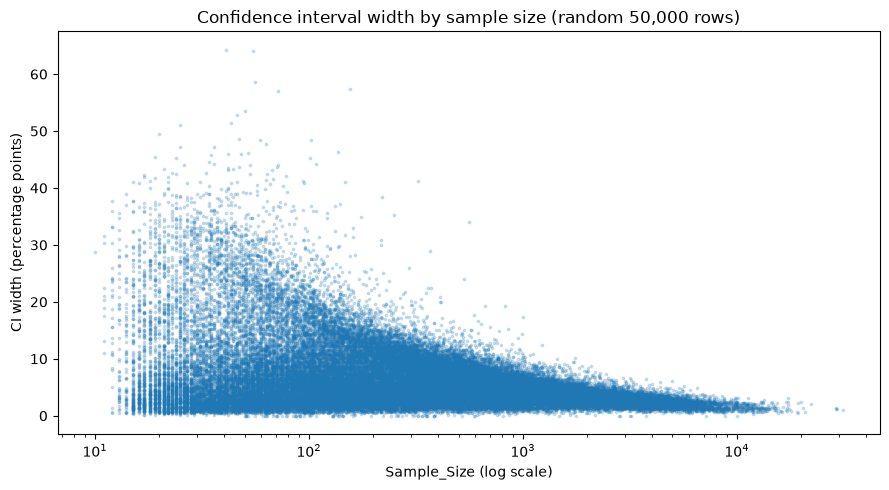

In [24]:
plot_rows = with_value.dropna(subset=["ci_width"])
plot_rows = plot_rows.sample(min(50_000, len(plot_rows)), random_state=1)

fig, ax = plt.subplots(figsize=(9, 5))
# s sets the dot size, alpha makes dots partly see-through so dense areas look darker
ax.scatter(plot_rows["Sample_Size"], plot_rows["ci_width"], s=3, alpha=0.2)
# a log scale spreads out the small sample sizes, where most rows sit
ax.set_xscale("log")
ax.set_title("Confidence interval width by sample size (random 50,000 rows)")
ax.set_xlabel("Sample_Size (log scale)")
ax.set_ylabel("CI width (percentage points)")
plt.tight_layout()
plt.show()

## 9. Summary for widget design

Fill in after running the notebook. Each line lists the section that answers it.

| Widget | Decision | From section |
|---|---|---|
| Class, Topic, Question dropdowns | Dependent dropdowns possible? | 2 |
| Response dropdown | Needed for all questions, or only multi-response ones? | 3 |
| Year selector | Fixed 2011 to 2025, or range set by the chosen question? | 4 |
| State dropdown | States and DC only, or territories too? Median as reference line? | 5 |
| Break-out category and group | Two-step selector, how to handle income and unusual age groups | 6 |
| Warnings or hidden choices | Which groups or states are mostly missing | 7 |
| Sample size filter or error bars | Worth adding? | 8 |